# 05 — Edges, votes, and professional liars

A noisy image hides structure. Filters calm the noise, edge detectors reveal boundaries, the Hough transform lets edge pixels vote for lines, and RANSAC fits a model while refusing to trust everybody.

Our route is deliberately visual:

**noisy pixels → smoothing → edges → line evidence → robust fitting**

Least squares will appear only when it has a job to do. No one will be asked to admire a wall of derivatives for character development.

### Philosophical digression — what is this notebook really about?

Mostly, it is about finding meaningful lines in images—but the reusable story is broader: **calm the noise → extract useful evidence → fit a geometric model → survive bad evidence**. Hough works with image edges; least squares and RANSAC work with point coordinates, but all three are trying to turn an untidy crowd of measurements into structure.

Today that structure is a line. Another day it might be a circle, a plane, a camera transformation, or some other geometric creature demanding attention.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=3, suppress=True)
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

OpenCV 4.14.0 | NumPy 2.5.4


## 1. Manufacture a small road crime scene

We use a synthetic grayscale scene so we know which structures are real and which pixels are merely making trouble. The diagonal lines will become our road-like targets; two suspiciously well-groomed trees provide curved and vertical boundaries so the algorithms cannot claim the exam was unfair.

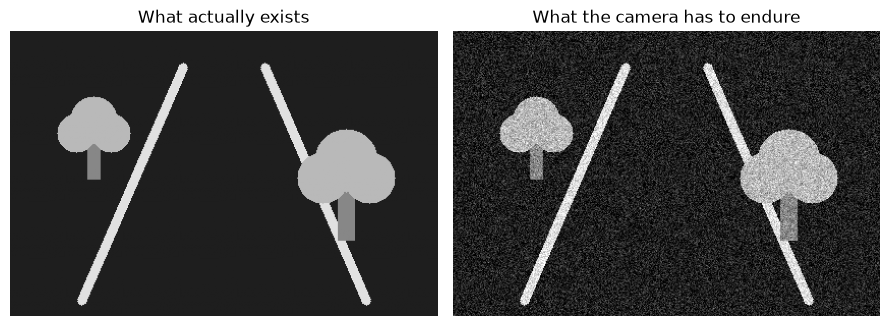

In [2]:
def make_line_scene(height=280, width=420, noise_sigma=28, seed=12):
    """Create a clean line scene and a reproducibly noisy observation."""
    clean = np.full((height, width), 30, dtype=np.uint8)
    cv2.line(clean, (70, height - 15), (170, 35), 225, 7)
    cv2.line(clean, (350, height - 15), (250, 35), 225, 7)

    def draw_tree(image, x, ground_y, scale=1.0):
        """Draw a tiny grayscale tree that has not yet discovered photosynthesis."""
        trunk_half_width = round(7 * scale)
        trunk_height = round(48 * scale)
        cv2.rectangle(
            image,
            (x - trunk_half_width, ground_y - trunk_height),
            (x + trunk_half_width, ground_y),
            135,
            -1,
        )

        crown_y = ground_y - trunk_height
        for dx, dy, radius in ((0, -20, 27), (-20, -5, 22), (20, -5, 22)):
            cv2.circle(
                image,
                (x + round(dx * scale), crown_y + round(dy * scale)),
                round(radius * scale),
                185,
                -1,
            )

    draw_tree(clean, x=82, ground_y=145, scale=0.85)
    draw_tree(clean, x=330, ground_y=205, scale=1.15)

    rng = np.random.default_rng(seed)
    noise = rng.normal(0, noise_sigma, clean.shape)
    noisy = np.clip(clean.astype(float) + noise, 0, 255).astype(np.uint8)
    return clean, noisy


clean_scene, noisy_scene = make_line_scene()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, image, title in zip(
    axes,
    (clean_scene, noisy_scene),
    ("What actually exists", "What the camera has to endure"),
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Smoothing: ask neighbouring pixels to calm down

A filter kernel is a tiny grid that slides over the image. At every position it combines neighbouring pixels into a new value. This sliding weighted sum is **convolution**—although OpenCV usually handles the actual arithmetic while we retain our remaining daylight.

A **box filter** gives every neighbour equal influence. A **Gaussian filter** gives nearby pixels more influence than distant ones. Both reduce noise, but both also soften boundaries. Smoothing is therefore negotiation, not free cleaning.

> Further reading to provide comfort through its mere existence: [OpenCV image filtering](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).

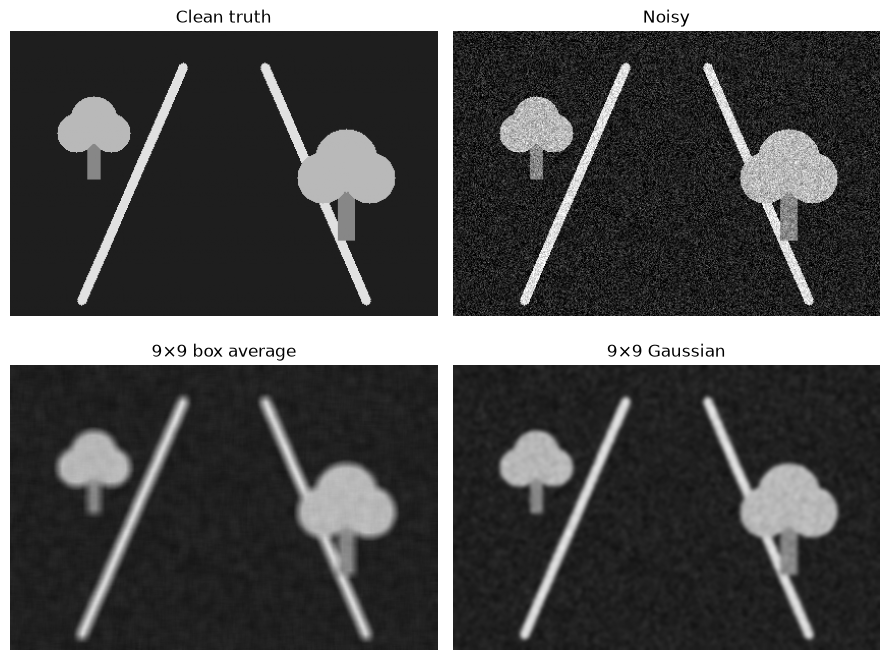

In [3]:
box_blur = cv2.blur(noisy_scene, (9, 9))
gaussian_blur = cv2.GaussianBlur(noisy_scene, (9, 9), sigmaX=2.0)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes = axes.ravel()
for ax, image, title in zip(
    axes,
    (clean_scene, noisy_scene, box_blur, gaussian_blur),
    ("Clean truth", "Noisy", "9×9 box average", "9×9 Gaussian"),
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Border highlighting: look for sudden change

An edge is a place where brightness changes quickly. Derivative filters approximate that change using neighbouring pixels:

- **Sobel X** reacts strongly to left–right brightness change, so it highlights mostly vertical borders.
- **Sobel Y** reacts to top–bottom change, so it highlights mostly horizontal borders.
- Combining both gives gradient magnitude: *how strong is the change, regardless of direction?*
- **Canny** turns this into a thin binary edge map and applies additional rules so every mild complaint does not become an edge.

> Official reading for people who wish to know what the demon does after smoothing: [Sobel derivatives](https://docs.opencv.org/4.x/d2/d2c/tutorial_sobel_derivatives.html) and [Canny edge detection](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html).

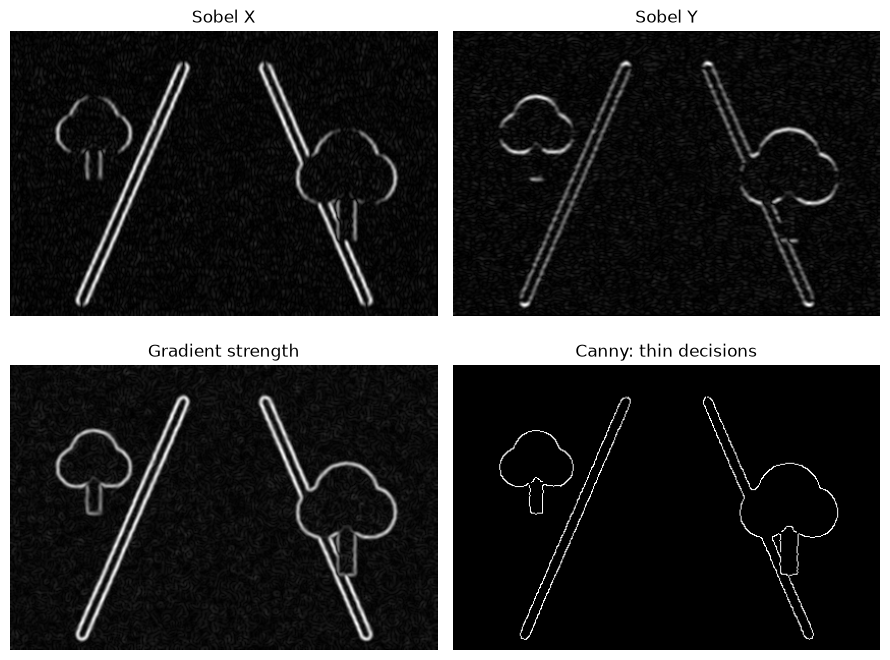

In [4]:
smoothed_for_edges = cv2.GaussianBlur(noisy_scene, (7, 7), sigmaX=1.4)
sobel_x = cv2.Sobel(smoothed_for_edges, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(smoothed_for_edges, cv2.CV_32F, 0, 1, ksize=3)
gradient_magnitude = cv2.magnitude(sobel_x, sobel_y)
edge_map = cv2.Canny(smoothed_for_edges, threshold1=50, threshold2=130)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes = axes.ravel()
images = (np.abs(sobel_x), np.abs(sobel_y), gradient_magnitude, edge_map)
titles = ("Sobel X", "Sobel Y", "Gradient strength", "Canny: thin decisions")
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Least squares: the line of minimum collective embarrassment

Suppose the points almost form a line but measurement noise moves them around. For any proposed line, each point has a residual—here, its vertical distance from the line. Least squares chooses the line with the smallest **sum of squared residuals**.

Why squares? Positive and negative errors cannot cancel, and large mistakes receive a large penalty. That second property is useful until an outlier arrives with a dramatic personality: one enormous error can pull the fitted line toward it.

That is the whole idea required for this notebook. The algebra may continue existing independently without our supervision.

> In the rare, almost impossible case that this is not enough: Penn State's [Simple Linear Regression — What Is the Best Fitting Line?](https://online.stat.psu.edu/stat501/Lesson01) contains the derivation and formulas, while its serious name provides comfort through its mere existence.

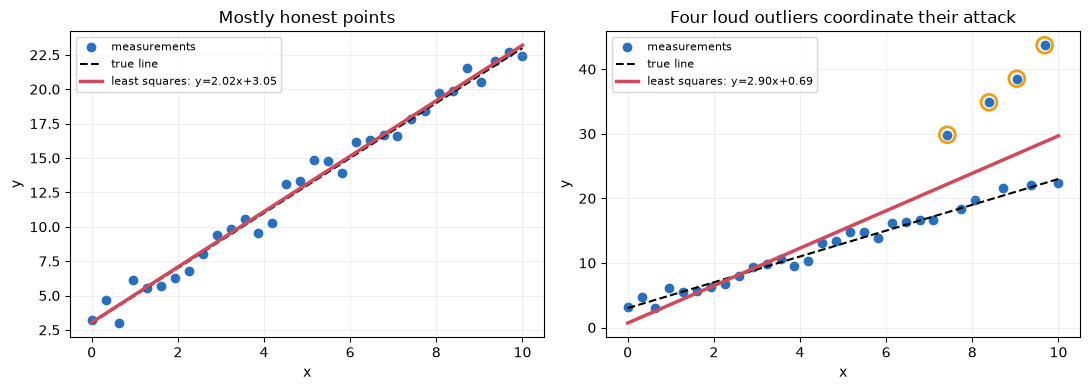

In [5]:
rng = np.random.default_rng(21)
x_points = np.linspace(0, 10, 32)
true_y = 2.0 * x_points + 3.0
measured_y = true_y + rng.normal(0, 0.7, len(x_points))
outlier_indices = np.array([23, 26, 28, 30])
observed_y = measured_y.copy()
observed_y[outlier_indices] += np.array([12, 15, 18, 21])

clean_slope, clean_intercept = np.polyfit(x_points, measured_y, 1)
all_slope, all_intercept = np.polyfit(x_points, observed_y, 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y_values, slope, intercept, title in (
    (axes[0], measured_y, clean_slope, clean_intercept, "Mostly honest points"),
    (axes[1], observed_y, all_slope, all_intercept, "Four loud outliers coordinate their attack"),
):
    ax.scatter(x_points, y_values, color="#276FBF", label="measurements")
    ax.plot(x_points, true_y, "k--", label="true line")
    ax.plot(x_points, slope * x_points + intercept, color="#D1495B", linewidth=2.5,
            label=f"least squares: y={slope:.2f}x+{intercept:.2f}")
    ax.set(xlabel="x", ylabel="y", title=title)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[1].scatter(x_points[outlier_indices], observed_y[outlier_indices],
                facecolors="none", edgecolors="#F39C12", s=130, linewidth=2, label="outliers")
plt.tight_layout()
plt.show()

## 5. RANSAC: trust small groups, then demand witnesses

**RANdom SAmple Consensus** repeatedly performs a small audition—in our experiment, up to 250 times:

1. Randomly pick two points, the minimum needed to define a 2D line.
2. Draw the only candidate line passing through them.
3. Measure how far every point is from that line.
4. Count the points within the allowed distance. Those supporters are **inliers**.
5. Remember the candidate supported by the most inliers. Some attempts find two honest points; others produce complete geometric nonsense.
6. After the auditions, take the winning inlier group and fit it with ordinary least squares to produce a cleaner final line.

RANSAC does not average its 250 candidate lines and it does not magically identify truth. It assumes that honest evidence is common enough for at least one lucky sample to contain only inliers. Its important knobs are the allowed residual distance and number of trials.

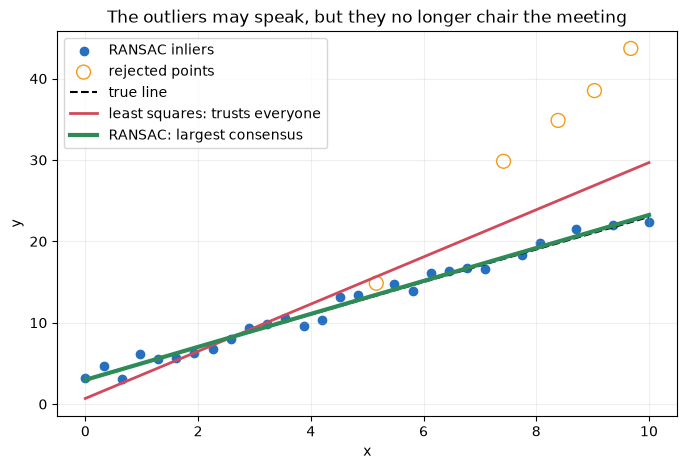

Least squares: slope=2.90, intercept=0.69
RANSAC:       slope=2.03, intercept=2.98
RANSAC kept 27 of 32 points as inliers


In [6]:
def fit_line_ransac(x, y, residual_threshold=1.3, trials=250, seed=5):
    """Fit y = ax + b by random sampling and largest consensus."""
    rng = np.random.default_rng(seed)
    best_inliers = np.zeros(len(x), dtype=bool)
    for _ in range(trials):
        first, second = rng.choice(len(x), size=2, replace=False)
        if x[first] == x[second]:
            continue
        slope = (y[second] - y[first]) / (x[second] - x[first])
        intercept = y[first] - slope * x[first]
        inliers = np.abs(y - (slope * x + intercept)) <= residual_threshold
        if inliers.sum() > best_inliers.sum():
            best_inliers = inliers

    slope, intercept = np.polyfit(x[best_inliers], y[best_inliers], 1)
    return slope, intercept, best_inliers


ransac_slope, ransac_intercept, ransac_inliers = fit_line_ransac(x_points, observed_y)
least_squares_line = all_slope * x_points + all_intercept
ransac_line = ransac_slope * x_points + ransac_intercept

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_points[ransac_inliers], observed_y[ransac_inliers], color="#276FBF", label="RANSAC inliers")
ax.scatter(x_points[~ransac_inliers], observed_y[~ransac_inliers],
           facecolors="none", edgecolors="#F39C12", s=100, label="rejected points")
ax.plot(x_points, true_y, "k--", label="true line")
ax.plot(x_points, least_squares_line, color="#D1495B", linewidth=2, label="least squares: trusts everyone")
ax.plot(x_points, ransac_line, color="#2E8B57", linewidth=3, label="RANSAC: largest consensus")
ax.set(xlabel="x", ylabel="y", title="The outliers may speak, but they no longer chair the meeting")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

print(f"Least squares: slope={all_slope:.2f}, intercept={all_intercept:.2f}")
print(f"RANSAC:       slope={ransac_slope:.2f}, intercept={ransac_intercept:.2f}")
print(f"RANSAC kept {ransac_inliers.sum()} of {len(x_points)} points as inliers")

## 6. Hough transform: let every edge pixel vote

The mysterious name is simply inherited from its inventor, Paul Hough. It is a surname, not an acronym designed to frighten innocent image pixels.

A line is represented by its angle `θ` and perpendicular distance `ρ` from the origin. We do not ask every image pixel to participate—only the white **edge pixels** produced by Canny. One such pixel could belong to many possible lines, so it votes for every `(θ, ρ)` pair describing a line through it. In our simple implementation, that means trying every allowed angle and calculating the one `ρ` that makes the line pass through the pixel.

One image point therefore becomes a curve in Hough parameter space. Points lying on the same image line produce curves that cross at one shared `(θ, ρ)`. A busy crossing in the vote accumulator means: *many edge pixels agree that this line exists.*

A useful mental model is an election: **a pixel does not know which line it belongs to, so it votes for every plausible one. Real lines win because many pixels independently vote for the same answer.** The accumulator plot is the election result—bright spots are winning lines; the darker regions are unsuccessful geometric political parties.

> It sounds unnecessarily abstract until the curves meet. Then it becomes merely strange. [OpenCV Hough line tutorial](https://docs.opencv.org/4.x/d6/d10/tutorial_py_houghlines.html).

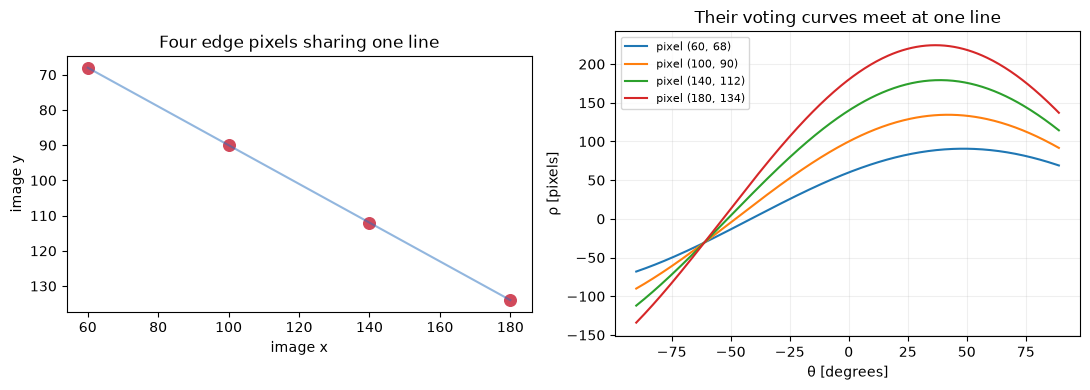

In [7]:
line_x = np.array([60, 100, 140, 180])
line_y = 0.55 * line_x + 35
theta_degrees = np.linspace(-90, 89, 360)
theta_radians = np.deg2rad(theta_degrees)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(line_x, line_y, s=70, color="#D1495B")
axes[0].plot(line_x, line_y, color="#276FBF", alpha=0.5)
axes[0].invert_yaxis()
axes[0].set_aspect("equal")
axes[0].set(xlabel="image x", ylabel="image y", title="Four edge pixels sharing one line")

for x, y in zip(line_x, line_y):
    rho_curve = x * np.cos(theta_radians) + y * np.sin(theta_radians)
    axes[1].plot(theta_degrees, rho_curve, label=f"pixel ({x:.0f}, {y:.0f})")
axes[1].set(xlabel="θ [degrees]", ylabel="ρ [pixels]",
            title="Their voting curves meet at one line")
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### From votes to detected lines

The accumulator is just a 2D table indexed by `(ρ, θ)`. Every edge pixel adds votes. Bright peaks are parameter pairs supported by many pixels. OpenCV then performs the same general idea efficiently and can return finite line segments with `HoughLinesP`.

The threshold is political: a low value allows minor parties and nonsense lines; a high value recognizes only candidates with a large coalition.

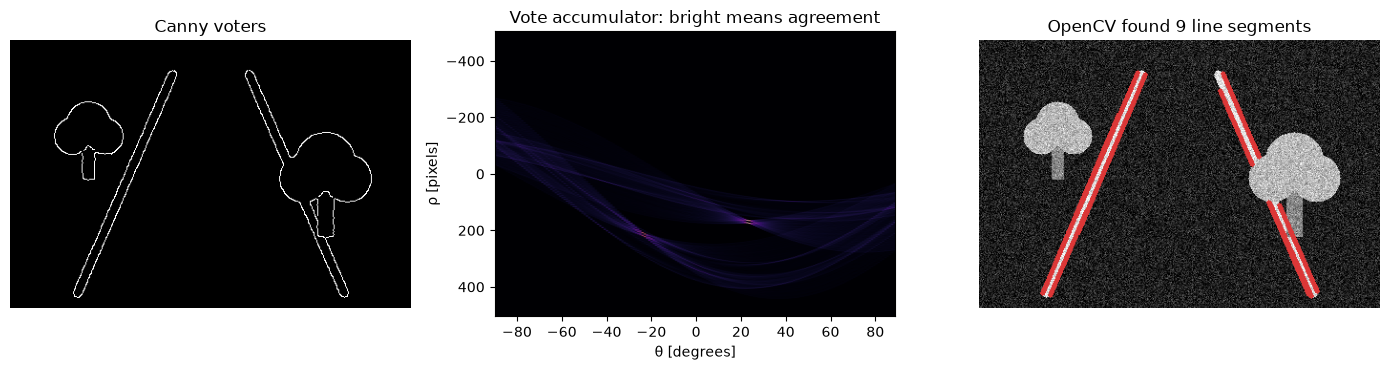

In [29]:
def hough_accumulator(edge_image, theta_degrees=np.arange(-90, 90)):
    """Build a basic rho-theta vote accumulator for a binary edge image."""
    y_pixels, x_pixels = np.nonzero(edge_image)
    diagonal = int(np.ceil(np.hypot(*edge_image.shape)))
    rhos = np.arange(-diagonal, diagonal + 1)
    accumulator = np.zeros((len(rhos), len(theta_degrees)), dtype=np.uint32)
    theta_radians = np.deg2rad(theta_degrees)

    for theta_index, theta in enumerate(theta_radians):
        rho_indices = np.rint(
            x_pixels * np.cos(theta) + y_pixels * np.sin(theta)
        ).astype(int) + diagonal
        np.add.at(accumulator[:, theta_index], rho_indices, 1)
    return accumulator, rhos, np.asarray(theta_degrees)


accumulator, rhos, hough_thetas = hough_accumulator(edge_map)
detected = cv2.HoughLinesP(
    edge_map,
    rho=1,
    theta=np.pi / 180,
    threshold=55,
    minLineLength=70,
    maxLineGap=18,
)
line_overlay = cv2.cvtColor(noisy_scene, cv2.COLOR_GRAY2RGB)
segment_overlay = line_overlay.copy()
segment_colors = (plt.get_cmap("tab10")(np.arange(10))[:, :3] * 255).astype(np.uint8)
if detected is not None:
    for segment_number, (x1, y1, x2, y2) in enumerate(detected[:, 0], start=1):
        color = tuple(int(channel) for channel in segment_colors[(segment_number - 1) % 10])
        midpoint = ((x1 + x2) // 2 + 4, (y1 + y2) // 2 - 4)
        cv2.line(line_overlay, (x1, y1), (x2, y2), (220, 55, 55), 3)
        cv2.line(segment_overlay, (x1, y1), (x2, y2), color, 4)
        cv2.putText(segment_overlay, str(segment_number), midpoint, cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (15, 15, 15), 3, cv2.LINE_AA)
        cv2.putText(segment_overlay, str(segment_number), midpoint, cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, color, 1, cv2.LINE_AA)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].imshow(edge_map, cmap="gray")
axes[0].set_title("Canny voters")
axes[1].imshow(
    accumulator,
    cmap="magma",
    aspect="auto",
    extent=(hough_thetas[0], hough_thetas[-1], rhos[-1], rhos[0]),
)
axes[1].set(xlabel="θ [degrees]", ylabel="ρ [pixels]", title="Vote accumulator: bright means agreement")
axes[2].imshow(line_overlay)
axes[2].set_title(f"OpenCV found {0 if detected is None else len(detected)} line segments")
for ax in (axes[0], axes[2]):
    ax.axis("off")
plt.tight_layout()
plt.show()

**Why nine segments when the scene has only two road markings?** A thick marking gives Canny two edges, and one physical edge may be returned as several overlapping or disconnected segments. Straight pieces of other objects may also qualify. `HoughLinesP` reports every fragment that passes `threshold`, `minLineLength`, and `maxLineGap`; it does not yet understand that several fragments belong to the same civilized road boundary.

Below each returned segment has its own color and number; where colors lie almost on top of one another, OpenCV has reported overlapping opinions about the same physical edge. 

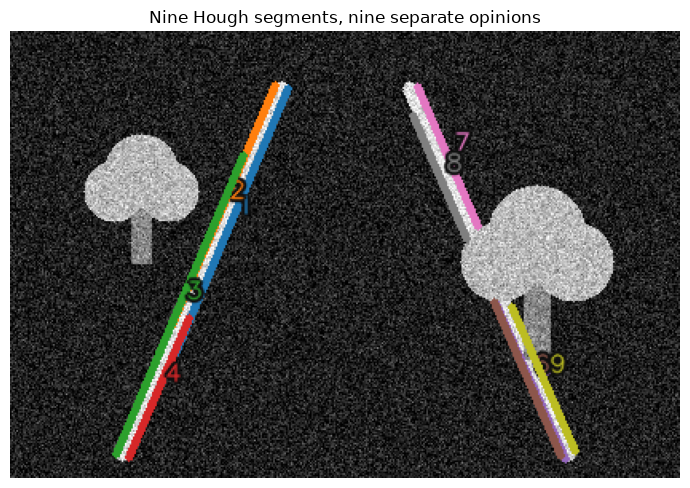

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(segment_overlay)
ax.set_title("Nine Hough segments, nine separate opinions")
ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Hough and RANSAC are related, not interchangeable

- **Hough:** many edge pixels vote in a discretized parameter space. It is excellent for finding several lines or shapes in an image, but resolution and thresholds affect the result.
- **RANSAC:** repeatedly proposes a model from a minimal random sample and asks how many data points support it. It is excellent when a point set contains outliers and we want one or a few models.
- **Least squares:** uses all points and gives a clean final estimate when the evidence is mostly honest. It is often used *after* RANSAC identifies the inliers.

A practical pipeline may use edges to generate evidence, Hough or RANSAC to discover structure, and least squares to polish the survivors. The algorithms are colleagues, not rival cults.

## Practice experiments

Choose whichever looks interesting; this is not a mandatory tour of every knob:

1. Increase `noise_sigma` and compare box versus Gaussian smoothing before Canny.
2. Change the two Canny thresholds and watch weak edges disappear—or every noisy pixel receive a promotion.
3. Change `HoughLinesP` threshold, minimum line length, and maximum gap. Try to make it hallucinate.
4. Add more line-fitting outliers, then vary the RANSAC residual threshold and trial count.
5. Replace the synthetic road with a simple photograph containing strong straight lines.

## Quick reflection

- Why can smoothing help edge detection, and what detail can it destroy?
- Why does Sobel X emphasize mostly vertical borders?
- Why can a few distant outliers pull a least-squares line strongly?
- What does an inlier mean to RANSAC?
- What does a bright peak in a Hough accumulator mean?
- When might you choose Hough instead of RANSAC?

## Takeaway

Filters convert local pixel neighbourhoods into useful evidence. Hough gathers votes from many edge pixels; RANSAC searches for a model with a trustworthy crowd; least squares gives that crowd a precise final line.

The pixels were noisy, the outliers lied, and geometry survived anyway.